<a href="https://colab.research.google.com/github/aarushi-202618017/202618017_Aarushi_DS605/blob/main/202618017_LAB_07/202618017_LAB_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Download Dataset

In [1]:
import kagglehub
path = kagglehub.dataset_download("kasikrit/att-database-of-faces")
print("Path to dataset files:", path)

100%|██████████| 3.61M/3.61M [00:00<00:00, 149MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/kasikrit/att-database-of-faces/versions/2


# Part A - Image Representation

In [2]:
import os
import glob
import cv2
import numpy as np

image_mats = []
labels = []

entries = sorted(os.listdir(path))
subfolders = [e for e in entries if os.path.isdir(os.path.join(path, e))]

if subfolders:
    for label, subfolder in enumerate(subfolders):
        folder_path = os.path.join(path, subfolder)

        for file_name in os.listdir(folder_path):
            if file_name.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.pgm')):
                file_path = os.path.join(folder_path, file_name)

                img = cv2.imread(file_path)
                if img is None:
                    continue

                img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

                image_mats.append(img_gray)
                labels.append(label)

images = np.array(image_mats, dtype=np.float32)
labels = np.array(labels, dtype=np.int32)

N, H, W = images.shape
D = H * W

In [8]:
images_normalized = images / 255.0 if images.max() > 1.0 else images.copy()

print(f"Total Images Loaded (N): {N}")
print(f"Total Subjects/Classes: {len(np.unique(labels))}")
print(f"Grayscale Dimensions:   {H} x {W} pixels")
print(f"Raw Intensity Range:    Min = {images.min():.1f}, Max = {images.max():.1f}")
print(f"Normalized Range:       Min = {images_normalized.min():.2f}, Max = {images_normalized.max():.2f}")

X_flat = images_normalized.reshape(N, D)
print(f"Flattened Image Matrix: {X_flat.shape} (N images x D features)")

np.random.seed(42)
test_ratio = 0.2

train_indices, test_indices = [], []

for subject_id in np.unique(labels):
    subject_mask = np.where(labels == subject_id)[0]
    np.random.shuffle(subject_mask)

    n_test = max(1, int(len(subject_mask) * test_ratio))
    test_indices.extend(subject_mask[:n_test])
    train_indices.extend(subject_mask[n_test:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

X_train, y_train = X_flat[train_indices], labels[train_indices]
X_test, y_test   = X_flat[test_indices], labels[test_indices]

print()
print(f"X_train Matrix Shape: {X_train.shape}")
print(f"X_test Matrix Shape:  {X_test.shape}")
print(f"Subjects in Train Set: {len(np.unique(y_train))}/{len(np.unique(labels))}")
print(f"Subjects in Test Set:  {len(np.unique(y_test))}/{len(np.unique(labels))}")

Total Images Loaded (N): 400
Total Subjects/Classes: 40
Grayscale Dimensions:   112 x 92 pixels
Raw Intensity Range:    Min = 0.0, Max = 251.0
Normalized Range:       Min = 0.00, Max = 0.98
Flattened Image Matrix: (400, 10304) (N images x D features)

X_train Matrix Shape: (320, 10304)
X_test Matrix Shape:  (80, 10304)
Subjects in Train Set: 40/40
Subjects in Test Set:  40/40


# Part B - PCA, Eigenfaces and Compression

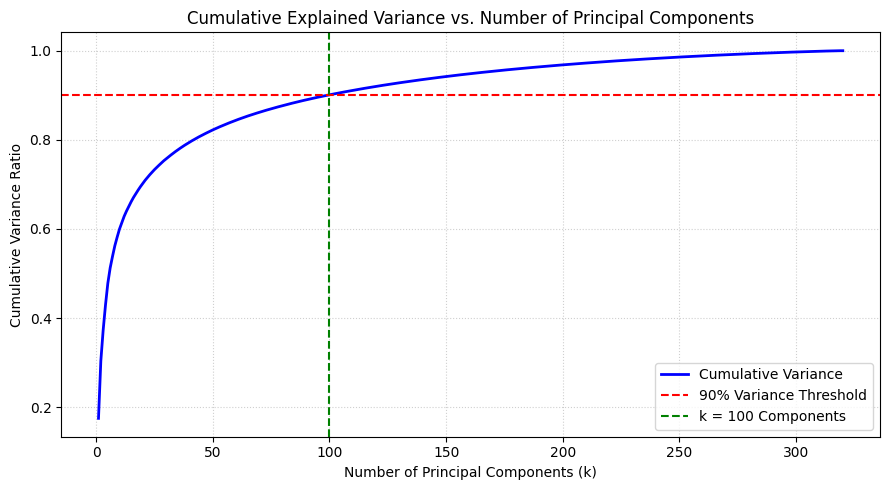

In [9]:
import numpy as np
import matplotlib.pyplot as plt

mean_face = np.mean(X_train, axis=0)

X_train_centered = X_train - mean_face
X_test_centered  = X_test - mean_face

N_train, D = X_train.shape

U, S, Vt_svd = np.linalg.svd(X_train_centered, full_matrices=False)

explained_variance_svd = (S ** 2) / (N_train - 1)
total_variance_svd = np.sum(explained_variance_svd)
var_ratio_svd = explained_variance_svd / total_variance_svd
cum_var_ratio_svd = np.cumsum(var_ratio_svd)

K = np.dot(X_train_centered, X_train_centered.T) / (N_train - 1)
eigvals_gram, eigvecs_gram = np.linalg.eigh(K)

sort_idx = np.argsort(eigvals_gram)[::-1]
eigvals_gram = np.maximum(eigvals_gram[sort_idx], 0)
eigvecs_gram = eigvecs_gram[:, sort_idx]

V_gram = np.dot(X_train_centered.T, eigvecs_gram)
V_gram = V_gram / np.linalg.norm(V_gram, axis=0, keepdims=True)
Vt_gram = V_gram.T

cos_sim = np.abs(np.sum(Vt_svd[:10] * Vt_gram[:10], axis=1))

k_90 = np.argmax(cum_var_ratio_svd >= 0.90) + 1

plt.figure(figsize=(9, 5))
plt.plot(np.arange(1, len(cum_var_ratio_svd) + 1), cum_var_ratio_svd, color='blue', linewidth=2, label='Cumulative Variance')
plt.axhline(y=0.90, color='red', linestyle='--', linewidth=1.5, label='90% Variance Threshold')
plt.axvline(x=k_90, color='green', linestyle='--', linewidth=1.5, label=f'k = {k_90} Components')
plt.title('Cumulative Explained Variance vs. Number of Principal Components', fontsize=12)
plt.xlabel('Number of Principal Components (k)', fontsize=10)
plt.ylabel('Cumulative Variance Ratio', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('explained_variance.png', dpi=300)
plt.show()

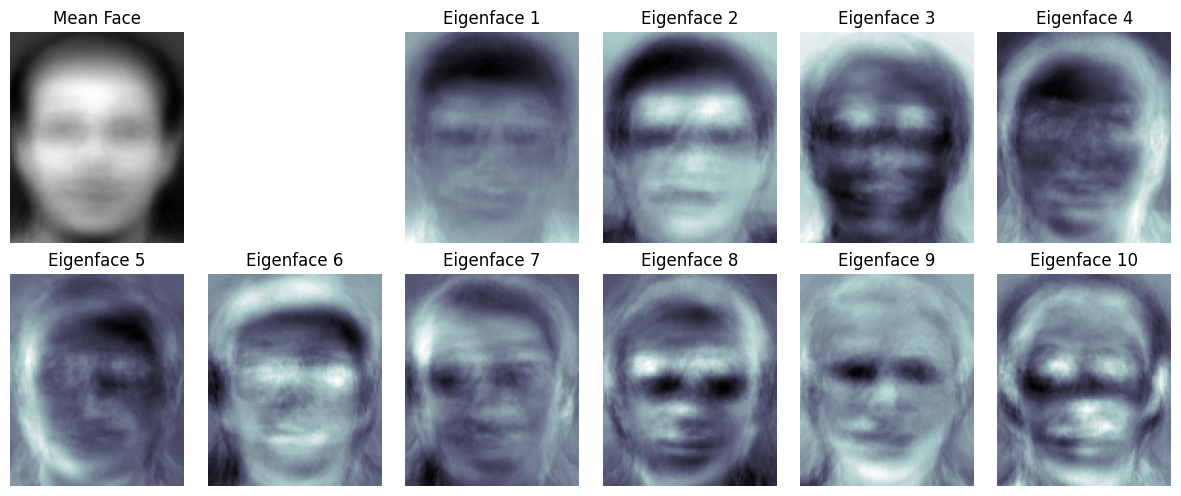

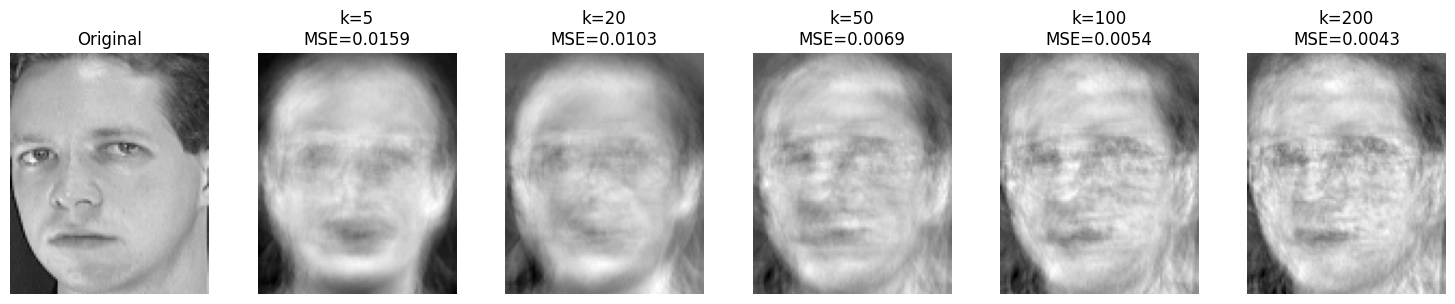

Original dimension per image: 10304 floats
Reduced dimension per image:  100 floats
Compression ratio:            103.04x


In [10]:
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 6, figsize=(12, 5))
axes[0, 0].imshow(mean_face.reshape(H, W), cmap='gray')
axes[0, 0].set_title('Mean Face')
axes[0, 0].axis('off')
axes[0, 1].axis('off')

for i in range(10):
    row = (i + 2) // 6
    col = (i + 2) % 6
    axes[row, col].imshow(Vt_svd[i].reshape(H, W), cmap='bone')
    axes[row, col].set_title(f'Eigenface {i+1}')
    axes[row, col].axis('off')

plt.tight_layout()
plt.savefig('eigenfaces.png', dpi=300)
plt.show()

Z_train = np.dot(X_train_centered, Vt_svd[:k_90].T)
Z_test  = np.dot(X_test_centered, Vt_svd[:k_90].T)

sample_idx = 0
sample_orig = X_test[sample_idx]
sample_centered = X_test_centered[sample_idx]

k_values = [5, 20, 50, k_90, 200]
fig, axes = plt.subplots(1, len(k_values) + 1, figsize=(15, 3))

axes[0].imshow(sample_orig.reshape(H, W), cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

for idx, k in enumerate(k_values):
    Z_sample = np.dot(sample_centered, Vt_svd[:k].T)
    rec_sample = np.dot(Z_sample, Vt_svd[:k]) + mean_face
    mse = np.mean((sample_orig - rec_sample) ** 2)

    axes[idx + 1].imshow(rec_sample.reshape(H, W), cmap='gray')
    axes[idx + 1].set_title(f'k={k}\nMSE={mse:.4f}')
    axes[idx + 1].axis('off')

plt.tight_layout()
plt.savefig('reconstruction.png', dpi=300)
plt.show()

orig_size_per_img = D
reduced_size_per_img = k_90
compression_ratio = orig_size_per_img / reduced_size_per_img

print(f"Original dimension per image: {orig_size_per_img} floats")
print(f"Reduced dimension per image:  {reduced_size_per_img} floats")
print(f"Compression ratio:            {compression_ratio:.2f}x")

# Part C - Recognition in PCA Space

Raw Pixel 1-NN Accuracy: 96.25%
PCA Space 1-NN Accuracy (k=100): 96.25%


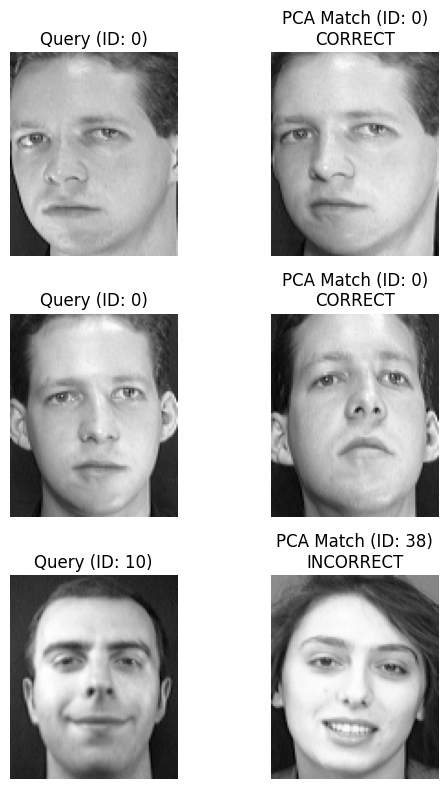

In [11]:
import numpy as np
import matplotlib.pyplot as plt

dists_pca = np.linalg.norm(Z_test[:, np.newaxis, :] - Z_train[np.newaxis, :, :], axis=2)
nn_indices_pca = np.argmin(dists_pca, axis=1)
y_pred_pca = y_train[nn_indices_pca]
acc_pca = np.mean(y_pred_pca == y_test)

dists_raw = np.linalg.norm(X_test[:, np.newaxis, :] - X_train[np.newaxis, :, :], axis=2)
nn_indices_raw = np.argmin(dists_raw, axis=1)
y_pred_raw = y_train[nn_indices_raw]
acc_raw = np.mean(y_pred_raw == y_test)

print(f"Raw Pixel 1-NN Accuracy: {acc_raw * 100:.2f}%")
print(f"PCA Space 1-NN Accuracy (k={k_90}): {acc_pca * 100:.2f}%")

correct_mask = np.where(y_pred_pca == y_test)[0]
incorrect_mask = np.where(y_pred_pca != y_test)[0]

fig, axes = plt.subplots(3, 2, figsize=(6, 8))

for i in range(min(2, len(correct_mask))):
    test_idx = correct_mask[i]
    train_idx = nn_indices_pca[test_idx]

    axes[i, 0].imshow(X_test[test_idx].reshape(H, W), cmap='gray')
    axes[i, 0].set_title(f"Query (ID: {y_test[test_idx]})")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(X_train[train_idx].reshape(H, W), cmap='gray')
    axes[i, 1].set_title(f"PCA Match (ID: {y_pred_pca[test_idx]})\nCORRECT")
    axes[i, 1].axis('off')

if len(incorrect_mask) > 0:
    test_idx = incorrect_mask[0]
    train_idx = nn_indices_pca[test_idx]

    axes[2, 0].imshow(X_test[test_idx].reshape(H, W), cmap='gray')
    axes[2, 0].set_title(f"Query (ID: {y_test[test_idx]})")
    axes[2, 0].axis('off')

    axes[2, 1].imshow(X_train[train_idx].reshape(H, W), cmap='gray')
    axes[2, 1].set_title(f"PCA Match (ID: {y_pred_pca[test_idx]})\nINCORRECT")
    axes[2, 1].axis('off')

plt.tight_layout()
plt.savefig('matching_results.png', dpi=300)
plt.show()

# Part D - Traditional Machine Learning

In [12]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

k_values = [10, 30, 50, k_90, 150]
results = []

classifiers = {
    "1-NN Baseline": KNeighborsClassifier(n_neighbors=1),
    "3-NN": KNeighborsClassifier(n_neighbors=3),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM (Linear)": SVC(kernel='linear', random_state=42),
    "SVM (RBF)": SVC(kernel='rbf', C=10.0, gamma='scale', random_state=42)
}

for k in k_values:
    Z_tr = np.dot(X_train_centered, Vt_svd[:k].T)
    Z_te = np.dot(X_test_centered, Vt_svd[:k].T)

    for name, clf in classifiers.items():
        clf.fit(Z_tr, y_train)
        y_pred = clf.predict(Z_te)
        acc = accuracy_score(y_test, y_pred) * 100

        results.append({
            "Model": name,
            "Components (k)": k,
            "Accuracy (%)": round(acc, 2)
        })

df_results = pd.DataFrame(results)
pivot_df = df_results.pivot(index="Model", columns="Components (k)", values="Accuracy (%)")
print(pivot_df)

Components (k)         10     30    50     100    150
Model                                                
1-NN Baseline        95.00  97.50  97.5  96.25  96.25
3-NN                 86.25  88.75  92.5  92.50  93.75
Logistic Regression  96.25  97.50  97.5  97.50  97.50
SVM (Linear)         96.25  97.50  97.5  97.50  97.50
SVM (RBF)            95.00  97.50  97.5  97.50  97.50
